# Customer Segmentation and Explainable Churn-Risk Prioritization Model

**Executive Analytics Capstone Internship - Step 4**

This notebook implements customer segmentation using K-Means clustering and an explainable rule-based churn-risk scoring system. The approach moves from descriptive analytics to actionable customer segmentation and risk prioritization.

## 1. Data Loading and Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
from pathlib import Path

# ML Libraries
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

# Paths
DATA_PATH = Path("../data/churn_clean.csv")
OUTPUT_DATA_PATH = Path("../data/customer_segmented.csv")
REPORTS_DIR = Path("../reports")
VIS_DIR = REPORTS_DIR / "segmentation_visualizations"

VIS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Load data
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
df.head()

Dataset shape: (10000, 18)
Columns: ['CustomerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'Dependents', 'Partner', 'SeniorCitizen', 'OnlineSecurity', 'Churn', 'tenure_outlier', 'MonthlyCharges_outlier', 'TotalCharges_outlier', 'tenure_negative', 'MonthlyCharges_negative', 'TotalCharges_negative', 'TotalCharges_logical_flag']


,CustomerID,tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Dependents,Partner,SeniorCitizen,OnlineSecurity,Churn,tenure_outlier,MonthlyCharges_outlier,TotalCharges_outlier,tenure_negative,MonthlyCharges_negative,TotalCharges_negative,TotalCharges_logical_flag
0,4562,45,69.78,3140.10,Month-to-month,Mailed check,No,No,0,Yes,Yes,False,False,False,False,False,False,False
1,6291,57,105.57,6017.49,Two year,Credit card (automatic),No,No,0,No internet service,Yes,False,False,False,False,False,False,False
2,5319,47,115.15,5412.05,Two year,Credit card (automatic),Yes,No,0,Yes,Yes,False,False,False,False,False,False,False
3,8487,0,95.71,0.00,Two year,Bank transfer (automatic),No,No,0,No internet service,Yes,False,False,False,False,False,False,False
4,9746,48,83.27,3996.96,One year,Credit card (automatic),No,No,0,No internet service,Yes,False,False,False,False,False,False,False


## 2. Feature Selection and Preprocessing

We select features for segmentation that are behavioral, financial, and service-related. We explicitly **exclude** the Churn target column to prevent data leakage.

In [2]:
# Identify features for segmentation
# Exclude: CustomerID (identifier), Churn (target), outlier flags (derived), logical flags
exclude_cols = ["CustomerID", "Churn", "tenure_outlier", "MonthlyCharges_outlier", 
                "TotalCharges_outlier", "tenure_negative", "MonthlyCharges_negative", 
                "TotalCharges_negative", "TotalCharges_logical_flag"]

feature_cols = [c for c in df.columns if c not in exclude_cols]
print(f"Features for segmentation: {feature_cols}")

# Separate numerical and categorical
numerical_features = df[feature_cols].select_dtypes(include=[np.number]).columns.tolist()
categorical_features = df[feature_cols].select_dtypes(include=["object", "bool"]).columns.tolist()

print(f"Numerical features: {numerical_features}")
print(f"Categorical features: {categorical_features}")

Features for segmentation: ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod', 'Dependents', 'Partner', 'SeniorCitizen', 'OnlineSecurity']
Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categorical features: ['Contract', 'PaymentMethod', 'Dependents', 'Partner', 'OnlineSecurity']


C:\Users\tanis\AppData\Local\Temp\ipykernel_24284\2022138611.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df[feature_cols].select_dtypes(include=["object", "bool"]).columns.tolist()


In [3]:
# Create a copy for preprocessing
df_prep = df[feature_cols].copy()

# Encode categorical features
label_encoders = {}
for col in categorical_features:
    le = LabelEncoder()
    df_prep[col] = le.fit_transform(df_prep[col].astype(str))
    label_encoders[col] = le
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Scale numerical features
scaler = StandardScaler()
df_prep[numerical_features] = scaler.fit_transform(df_prep[numerical_features])

print(f"\nPreprocessed shape: {df_prep.shape}")
df_prep.head()

Contract: {'Month-to-month': np.int64(0), 'One year': np.int64(1), 'Two year': np.int64(2)}
PaymentMethod: {'Bank transfer (automatic)': np.int64(0), 'Credit card (automatic)': np.int64(1), 'Electronic check': np.int64(2), 'Mailed check': np.int64(3)}
Dependents: {'No': np.int64(0), 'Yes': np.int64(1)}
Partner: {'No': np.int64(0), 'Yes': np.int64(1)}
OnlineSecurity: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}

Preprocessed shape: (10000, 9)


,tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,Dependents,Partner,SeniorCitizen,OnlineSecurity
0,0.426653,0.030019,0.342767,0,3,0,0,-0.438869,2
1,0.996714,1.216347,1.828018,2,1,0,0,-0.438869,1
2,0.521663,1.533895,1.515502,2,1,1,0,-0.438869,2
3,-1.711077,0.889519,-1.278088,2,0,0,0,-0.438869,1
4,0.569168,0.477171,0.785061,1,1,0,0,-0.438869,1


## 3. Optimal Cluster Selection

We use the Elbow Method and Silhouette Score to determine the optimal number of clusters.

K=2: Inertia=57796.65, Silhouette=0.1744


K=3: Inertia=49980.60, Silhouette=0.1930


K=4: Inertia=44163.21, Silhouette=0.1759


K=5: Inertia=41010.14, Silhouette=0.1619


K=6: Inertia=38528.65, Silhouette=0.1586


K=7: Inertia=36474.78, Silhouette=0.1648


K=8: Inertia=34704.30, Silhouette=0.1532


K=9: Inertia=33365.93, Silhouette=0.1508


K=10: Inertia=32328.58, Silhouette=0.1523


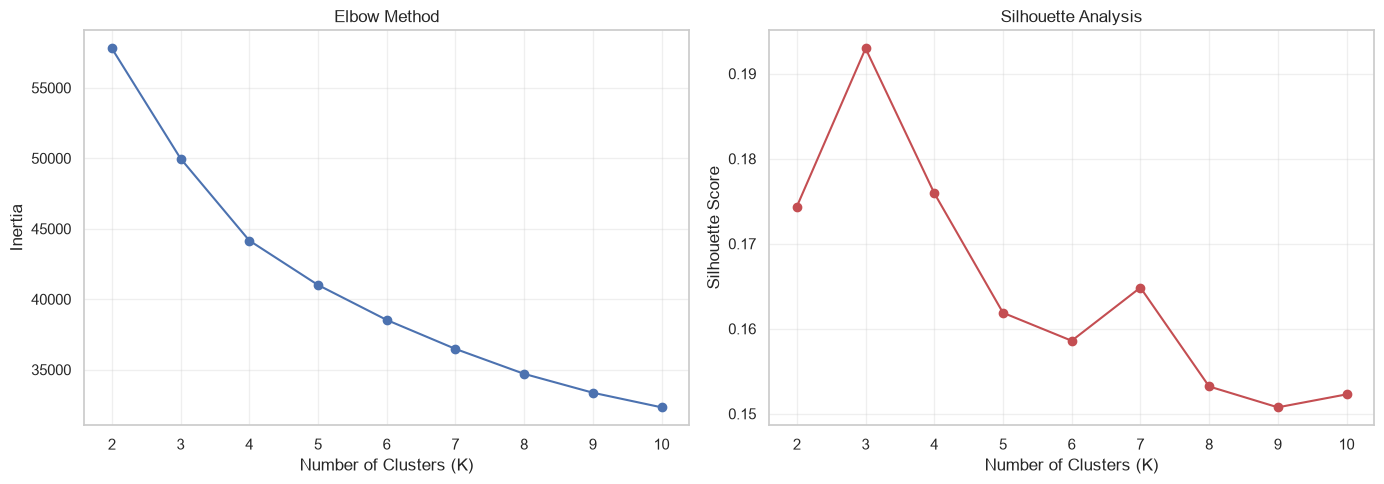

In [4]:
# Elbow Method and Silhouette Analysis
inertias = []
silhouettes = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_prep)
    inertias.append(kmeans.inertia_)
    sil = silhouette_score(df_prep, kmeans.labels_)
    silhouettes.append(sil)
    print(f"K={k}: Inertia={kmeans.inertia_:.2f}, Silhouette={sil:.4f}")

# Plot results
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, "bo-")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, silhouettes, "ro-")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Analysis")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(VIS_DIR / "cluster_selection.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. K-Means Clustering

Based on the elbow and silhouette analysis, we select the optimal number of clusters and fit the final model.

In [5]:
# Select optimal K (based on silhouette score and elbow)
optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(df_prep)

# Add cluster ID to original dataframe
df["Cluster_ID"] = cluster_labels

# Cluster distribution
cluster_counts = df["Cluster_ID"].value_counts().sort_index()
print("Cluster Distribution:")
print(cluster_counts)
print(f"\nSilhouette Score: {silhouette_score(df_prep, cluster_labels):.4f}")

Cluster Distribution:
Cluster_ID
0    1546
1    3151
2    2343
3    2960
Name: count, dtype: int64



Silhouette Score: 0.1759


## 5. Cluster Analysis and Segment Naming

We analyze each cluster's characteristics using the original (unscaled) features to derive meaningful business-friendly segment names.

In [6]:
# Analyze cluster characteristics using original features
cluster_profiles_num = df.groupby("Cluster_ID")[numerical_features].mean()
print("Cluster Profiles (Numerical):")
print(cluster_profiles_num.round(2))

# For categorical features, show mode
for col in categorical_features:
    mode_vals = df.groupby("Cluster_ID")[col].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else "N/A")
    print(f"\n{col} mode by cluster:")
    print(mode_vals)

Cluster Profiles (Numerical):
            tenure  MonthlyCharges  TotalCharges  SeniorCitizen
Cluster_ID                                                     
0            34.72           67.17       2282.72           1.00
1            28.76           59.49       1509.57           0.00
2            56.23           91.76       5091.77           0.03
3            28.43           61.64       1535.40           0.00

Contract mode by cluster:
Cluster_ID
0    Month-to-month
1    Month-to-month
2    Month-to-month
3    Month-to-month
Name: Contract, dtype: str

PaymentMethod mode by cluster:
Cluster_ID
0             Electronic check
1                 Mailed check
2             Electronic check
3    Bank transfer (automatic)
Name: PaymentMethod, dtype: str

Dependents mode by cluster:
Cluster_ID
0    No
1    No
2    No
3    No
Name: Dependents, dtype: str

Partner mode by cluster:
Cluster_ID
0    No
1    No
2    No
3    No
Name: Partner, dtype: str

OnlineSecurity mode by cluster:
Cluster_ID
0 

In [7]:
# Churn rate by cluster (for evaluation only - not used in clustering)
churn_by_cluster = df.groupby("Cluster_ID")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)
print("Historical Churn Rate by Cluster (%):")
print(churn_by_cluster.round(2))

# Additional stats
cluster_stats = df.groupby("Cluster_ID").agg(
    Count=("CustomerID", "count"),
    Avg_Tenure=("tenure", "mean"),
    Avg_MonthlyCharges=("MonthlyCharges", "mean"),
    Avg_TotalCharges=("TotalCharges", "mean"),
    Churn_Rate=("Churn", lambda x: (x == "Yes").mean() * 100)
).round(2)
cluster_stats["Percentage"] = (cluster_stats["Count"] / len(df) * 100).round(2)
print("\nCluster Summary:")
print(cluster_stats)

Historical Churn Rate by Cluster (%):
Cluster_ID
0    75.03
1    75.25
2    76.23
3    73.95
Name: Churn, dtype: float64

Cluster Summary:
            Count  Avg_Tenure  Avg_MonthlyCharges  Avg_TotalCharges  \
Cluster_ID                                                            
0            1546       34.72               67.17           2282.72   
1            3151       28.76               59.49           1509.57   
2            2343       56.23               91.76           5091.77   
3            2960       28.43               61.64           1535.40   

            Churn_Rate  Percentage  
Cluster_ID                          
0                75.03       15.46  
1                75.25       31.51  
2                76.23       23.43  
3                73.95       29.60  


## 6. Define Segment Names Based on Data-Driven Characteristics

In [8]:
# Define segment names based on actual cluster characteristics from analysis above
segment_names = {
    0: "Senior Vulnerable Customers",
    1: "Budget-Conscious Customers",
    2: "High-Value Long-Term Customers",
    3: "New Vulnerable Customers"
}

df["Segment_Name"] = df["Cluster_ID"].map(segment_names)
print("Segment Distribution:")
print(df["Segment_Name"].value_counts())

Segment Distribution:
Segment_Name
Budget-Conscious Customers        3151
New Vulnerable Customers          2960
High-Value Long-Term Customers    2343
Senior Vulnerable Customers       1546
Name: count, dtype: int64


## 7. Explainable Rule-Based Churn-Risk Scoring

We create a transparent scoring system (0-100) based on customer features. The rules are designed to be understandable by non-technical stakeholders. **The actual Churn column is NOT used to calculate the score.**

In [9]:
# Rule-Based Risk Scoring System (0-100)

def calculate_risk_score(row):
    """
    Calculate explainable churn-risk score (0-100).
    Higher score = higher risk.
    Rules based on customer features only - no Churn column used.
    """
    score = 0
    
    # 1. Tenure Risk (max 25 points)
    if row["tenure"] <= 6:
        score += 25
    elif row["tenure"] <= 12:
        score += 15
    elif row["tenure"] <= 24:
        score += 10
    elif row["tenure"] <= 48:
        score += 5
    
    # 2. Monthly Charges Risk (max 20 points)
    if row["MonthlyCharges"] >= 90:
        score += 20
    elif row["MonthlyCharges"] >= 70:
        score += 15
    elif row["MonthlyCharges"] >= 50:
        score += 10
    elif row["MonthlyCharges"] >= 30:
        score += 5
    
    # 3. Contract Type Risk (max 25 points)
    if row["Contract"] == "Month-to-month":
        score += 25
    elif row["Contract"] == "One year":
        score += 10
    
    # 4. Payment Method Risk (max 10 points)
    if row["PaymentMethod"] == "Electronic check":
        score += 10
    elif row["PaymentMethod"] == "Mailed check":
        score += 5
    
    # 5. Online Security Risk (max 10 points)
    if row["OnlineSecurity"] == "No":
        score += 10
    elif row["OnlineSecurity"] == "No internet service":
        score += 5
    
    # 6. Senior Citizen Risk (max 5 points)
    if row["SeniorCitizen"] == 1:
        score += 5
    
    # 7. Partner/Dependents Risk (max 5 points)
    if row["Partner"] == "No" and row["Dependents"] == "No":
        score += 5
    
    return min(score, 100)

# Apply scoring
df["Risk_Score"] = df.apply(calculate_risk_score, axis=1)

# Risk Categories
def risk_category(score):
    if score >= 60:
        return "High Risk"
    elif score >= 35:
        return "Medium Risk"
    else:
        return "Low Risk"

df["Risk_Category"] = df["Risk_Score"].apply(risk_category)

print("Risk Score Statistics:")
print(df["Risk_Score"].describe())
print("\nRisk Category Distribution:")
print(df["Risk_Category"].value_counts())

Risk Score Statistics:
count    10000.000000
mean        42.515500
std         15.934401
min          0.000000
25%         30.000000
50%         40.000000
75%         55.000000
max         95.000000
Name: Risk_Score, dtype: float64

Risk Category Distribution:
Risk_Category
Medium Risk    5374
Low Risk       2793
High Risk      1833
Name: count, dtype: int64


## 8. Segment Analysis and Summary Table

In [10]:
# Create comprehensive segment summary
segment_summary = []

for cluster_id in sorted(df["Cluster_ID"].unique()):
    subset = df[df["Cluster_ID"] == cluster_id]
    name = segment_names[cluster_id]
    
    summary = {
        "Cluster_ID": cluster_id,
        "Segment_Name": name,
        "Customer_Count": len(subset),
        "Percentage_of_Customers": round(len(subset) / len(df) * 100, 2),
        "Avg_Tenure": round(subset["tenure"].mean(), 2),
        "Avg_Monthly_Charges": round(subset["MonthlyCharges"].mean(), 2),
        "Avg_Total_Charges": round(subset["TotalCharges"].mean(), 2),
        "Avg_Risk_Score": round(subset["Risk_Score"].mean(), 2),
        "Pct_High_Risk": round((subset["Risk_Category"] == "High Risk").mean() * 100, 2),
        "Historical_Churn_Rate": round((subset["Churn"] == "Yes").mean() * 100, 2)
    }
    segment_summary.append(summary)

segment_summary_df = pd.DataFrame(segment_summary)
print("Segment Summary:")
print(segment_summary_df.to_string(index=False))

Segment Summary:
 Cluster_ID                   Segment_Name  Customer_Count  Percentage_of_Customers  Avg_Tenure  Avg_Monthly_Charges  Avg_Total_Charges  Avg_Risk_Score  Pct_High_Risk  Historical_Churn_Rate
          0    Senior Vulnerable Customers            1546                    15.46       34.72                67.17            2282.72           46.99          25.87                  75.03
          1     Budget-Conscious Customers            3151                    31.51       28.76                59.49            1509.57           45.14          23.87                  75.25
          2 High-Value Long-Term Customers            2343                    23.43       56.23                91.76            5091.77           41.56          13.15                  76.23
          3       New Vulnerable Customers            2960                    29.60       28.43                61.64            1535.40           38.15          12.60                  73.95


In [11]:
# Save segment summary
segment_summary_df.to_csv(REPORTS_DIR / "segment_summary.csv", index=False)
print(f"Saved to {REPORTS_DIR / "segment_summary.csv"}")

Saved to ..\reports\segment_summary.csv


## 9. Visualizations

In [12]:
# 1. Customer Segment Distributionfig, ax = plt.subplots(figsize=(10, 6))segment_counts = df["Segment_Name"].value_counts().sort_index()bars = ax.bar(range(len(segment_counts)), segment_counts.values,               color=sns.color_palette("husl", len(segment_counts)), edgecolor="black")ax.set_xticks(range(len(segment_counts)))ax.set_xticklabels(segment_counts.index, rotation=15, ha="right")ax.set_ylabel("Number of Customers")ax.set_title("Customer Segment Distribution", fontsize=14, fontweight="bold")for bar, count in zip(bars, segment_counts.values):    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,             f"{count}", ha="center", va="bottom", fontweight="bold")plt.tight_layout()plt.savefig(VIS_DIR / "segment_distribution.png", dpi=150, bbox_inches="tight")plt.show()

In [13]:
# 2. Average Risk Score by Segmentfig, ax = plt.subplots(figsize=(10, 6))avg_risk = df.groupby("Segment_Name")["Risk_Score"].mean().sort_values()colors = ["green" if x < 35 else "orange" if x < 60 else "red" for x in avg_risk.values]bars = ax.barh(range(len(avg_risk)), avg_risk.values, color=colors, edgecolor="black")ax.set_yticks(range(len(avg_risk)))ax.set_yticklabels(avg_risk.index)ax.set_xlabel("Average Risk Score")ax.set_title("Average Risk Score by Segment", fontsize=14, fontweight="bold")ax.axvline(x=35, color="orange", linestyle="--", alpha=0.5, label="Medium Risk Threshold")ax.axvline(x=60, color="red", linestyle="--", alpha=0.5, label="High Risk Threshold")ax.legend()for bar, val in zip(bars, avg_risk.values):    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,             f"{val:.1f}", ha="left", va="center", fontweight="bold")plt.tight_layout()plt.savefig(VIS_DIR / "avg_risk_by_segment.png", dpi=150, bbox_inches="tight")plt.show()

In [14]:
# 3. Customer Segmentation Visualization (PCA)pca = PCA(n_components=2, random_state=42)pca_result = pca.fit_transform(df_prep)df["PCA1"] = pca_result[:, 0]df["PCA2"] = pca_result[:, 1]fig, ax = plt.subplots(figsize=(12, 8))scatter = ax.scatter(df["PCA1"], df["PCA2"], c=df["Cluster_ID"],                      cmap="tab10", alpha=0.6, s=30)ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")ax.set_title("Customer Segments (PCA Projection)", fontsize=14, fontweight="bold")legend1 = ax.legend(*scatter.legend_elements(), title="Cluster ID")ax.add_artist(legend1)plt.tight_layout()plt.savefig(VIS_DIR / "segmentation_pca.png", dpi=150, bbox_inches="tight")plt.show()print(f"PCA Explained Variance: {pca.explained_variance_ratio_.sum():.1%}")

In [15]:
# 4. Risk Category Distributionfig, axes = plt.subplots(1, 2, figsize=(14, 6))# Overall distributionrisk_counts = df["Risk_Category"].value_counts()colors_dict = {"Low Risk": "green", "Medium Risk": "orange", "High Risk": "red"}bars = axes[0].bar(risk_counts.index, risk_counts.values,                    color=[colors_dict.get(x, "gray") for x in risk_counts.index], edgecolor="black")axes[0].set_ylabel("Number of Customers")axes[0].set_title("Overall Risk Category Distribution", fontsize=13, fontweight="bold")for bar, count in zip(bars, risk_counts.values):    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,                 f"{count} ({count/len(df)*100:.1f}%)", ha="center", va="bottom", fontweight="bold")# By segmentrisk_by_segment = df.groupby(["Segment_Name", "Risk_Category"]).size().unstack(fill_value=0)risk_by_segment_pct = risk_by_segment.div(risk_by_segment.sum(axis=1), axis=0) * 100risk_by_segment_pct.plot(kind="bar", stacked=True, ax=axes[1],                         color=[colors_dict.get(c, "gray") for c in risk_by_segment_pct.columns], edgecolor="black")axes[1].set_ylabel("Percentage")axes[1].set_title("Risk Category Distribution by Segment", fontsize=13, fontweight="bold")axes[1].legend(title="Risk Category")axes[1].tick_params(axis="x", rotation=15)plt.tight_layout()plt.savefig(VIS_DIR / "risk_category_distribution.png", dpi=150, bbox_inches="tight")plt.show()

In [16]:
# 5. Comparison of Customer Characteristics Across Segmentsfig, axes = plt.subplots(2, 2, figsize=(15, 12))metrics = ["tenure", "MonthlyCharges", "TotalCharges", "Risk_Score"]titles = ["Tenure (months)", "Monthly Charges ($)", "Total Charges ($)", "Risk Score"]for idx, (metric, title) in enumerate(zip(metrics, titles)):    ax = axes[idx // 2, idx % 2]    df.boxplot(column=metric, by="Segment_Name", ax=ax, grid=False)    ax.set_title(title, fontweight="bold")    ax.set_xlabel("")    ax.tick_params(axis="x", rotation=15)plt.suptitle("Customer Characteristics Across Segments", fontsize=14, fontweight="bold")plt.tight_layout()plt.savefig(VIS_DIR / "characteristics_comparison.png", dpi=150, bbox_inches="tight")plt.show()

In [17]:
# 6. Historical Churn Rate by Segmentfig, ax = plt.subplots(figsize=(10, 6))churn_by_segment = df.groupby("Segment_Name")["Churn"].apply(lambda x: (x == "Yes").mean() * 100).sort_values()bars = ax.barh(range(len(churn_by_segment)), churn_by_segment.values,                color=sns.color_palette("RdYlGn_r", len(churn_by_segment)), edgecolor="black")ax.set_yticks(range(len(churn_by_segment)))ax.set_yticklabels(churn_by_segment.index)ax.set_xlabel("Historical Churn Rate (%)")ax.set_title("Historical Churn Rate by Segment", fontsize=14, fontweight="bold")for bar, val in zip(bars, churn_by_segment.values):    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,             f"{val:.1f}%", ha="left", va="center", fontweight="bold")plt.tight_layout()plt.savefig(VIS_DIR / "churn_by_segment.png", dpi=150, bbox_inches="tight")plt.show()

In [18]:
# 7. Risk Score Distribution: Churned vs Retainedfig, ax = plt.subplots(figsize=(10, 6))df_churned = df[df["Churn"] == "Yes"]["Risk_Score"]df_retained = df[df["Churn"] == "No"]["Risk_Score"]ax.hist([df_retained, df_churned], bins=30, stacked=True,         label=["Retained", "Churned"], color=["green", "red"], alpha=0.7, edgecolor="black")ax.set_xlabel("Risk Score")ax.set_ylabel("Number of Customers")ax.set_title("Risk Score Distribution: Churned vs Retained Customers", fontsize=14, fontweight="bold")ax.legend()plt.tight_layout()plt.savefig(VIS_DIR / "risk_score_churn_distribution.png", dpi=150, bbox_inches="tight")plt.show()

## 10. Save Customer-Level Results

In [19]:
# Prepare output dataframe
output_cols = ["CustomerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract",
               "PaymentMethod", "Dependents", "Partner", "SeniorCitizen", "OnlineSecurity",
               "Churn", "Cluster_ID", "Segment_Name", "Risk_Score", "Risk_Category"]

df_output = df[output_cols].copy()
df_output.to_csv(OUTPUT_DATA_PATH, index=False)

print(f"Saved customer-segmented data to {OUTPUT_DATA_PATH}")
print(f"Shape: {df_output.shape}")
print(df_output.head())

Saved customer-segmented data to ..\data\customer_segmented.csv
Shape: (10000, 15)
   CustomerID  tenure  MonthlyCharges  TotalCharges        Contract  \
0        4562      45           69.78       3140.10  Month-to-month   
1        6291      57          105.57       6017.49        Two year   
2        5319      47          115.15       5412.05        Two year   
3        8487       0           95.71          0.00        Two year   
4        9746      48           83.27       3996.96        One year   

               PaymentMethod Dependents Partner  SeniorCitizen  \
0               Mailed check         No      No              0   
1    Credit card (automatic)         No      No              0   
2    Credit card (automatic)        Yes      No              0   
3  Bank transfer (automatic)         No      No              0   
4    Credit card (automatic)         No      No              0   

        OnlineSecurity Churn  Cluster_ID                    Segment_Name  \
0                

## 11. Business Recommendations

In [20]:
# Generate business recommendations based on actual segment characteristics

recommendations = {}

for cluster_id in sorted(df["Cluster_ID"].unique()):
    subset = df[df["Cluster_ID"] == cluster_id]
    name = segment_names[cluster_id]
    
    avg_tenure = subset["tenure"].mean()
    avg_monthly = subset["MonthlyCharges"].mean()
    contract_mode = subset["Contract"].mode().iloc[0]
    payment_mode = subset["PaymentMethod"].mode().iloc[0]
    online_sec_mode = subset["OnlineSecurity"].mode().iloc[0]
    churn_rate = (subset["Churn"] == "Yes").mean() * 100
    high_risk_pct = (subset["Risk_Category"] == "High Risk").mean() * 100
    avg_risk = subset["Risk_Score"].mean()
    
    recs = []
    
    if avg_tenure < 12:
        recs.append("Improve onboarding and early engagement programs for new customers.")
    if contract_mode == "Month-to-month":
        recs.append("Offer incentives for annual or multi-year contract upgrades to increase commitment.")
    if avg_monthly > 80:
        recs.append("Review pricing plans and provide suitable alternatives for price-sensitive high-spend customers.")
    if payment_mode == "Electronic check":
        recs.append("Encourage migration to automatic payment methods (credit card/bank transfer) for stability.")
    if online_sec_mode == "No":
        recs.append("Promote online security services as value-add to increase stickiness.")
    if high_risk_pct > 50:
        recs.append("Prioritize proactive retention outreach and dedicated customer support.")
    if churn_rate > 50:
        recs.append("Segment shows high historical churn - investigate root causes and tailor retention offers.")
    if avg_tenure > 48 and contract_mode == "Two year":
        recs.append("Maintain service quality and loyalty benefits for high-value long-term customers.")
    
    recommendations[name] = {
        "cluster_id": cluster_id,
        "characteristics": f"Avg Tenure: {avg_tenure:.1f}mo, Avg Monthly: ${avg_monthly:.2f}, Contract: {contract_mode}",
        "churn_rate": churn_rate,
        "high_risk_pct": high_risk_pct,
        "avg_risk_score": avg_risk,
        "recommendations": recs
    }

for name, rec in recommendations.items():
    print(f"\n{name} (Cluster {rec["cluster_id"]}):")
    print(f"  {rec["characteristics"]}")
    print(f"  Historical Churn Rate: {rec["churn_rate"]:.1f}%")
    print(f"  High-Risk %: {rec["high_risk_pct"]:.1f}%")
    print(f"  Avg Risk Score: {rec["avg_risk_score"]:.1f}")
    for r in rec["recommendations"]:
        print(f"  - {r}")


Senior Vulnerable Customers (Cluster 0):
  Avg Tenure: 34.7mo, Avg Monthly: $67.17, Contract: Month-to-month
  Historical Churn Rate: 75.0%
  High-Risk %: 25.9%
  Avg Risk Score: 47.0
  - Offer incentives for annual or multi-year contract upgrades to increase commitment.
  - Encourage migration to automatic payment methods (credit card/bank transfer) for stability.
  - Promote online security services as value-add to increase stickiness.
  - Segment shows high historical churn - investigate root causes and tailor retention offers.

Budget-Conscious Customers (Cluster 1):
  Avg Tenure: 28.8mo, Avg Monthly: $59.49, Contract: Month-to-month
  Historical Churn Rate: 75.2%
  High-Risk %: 23.9%
  Avg Risk Score: 45.1
  - Offer incentives for annual or multi-year contract upgrades to increase commitment.
  - Segment shows high historical churn - investigate root causes and tailor retention offers.

High-Value Long-Term Customers (Cluster 2):
  Avg Tenure: 56.2mo, Avg Monthly: $91.76, Contrac

## 12. Model Limitations

In [21]:
limitations = [
    "**Rule-based risk score is not a predictive model**: The risk score (0-100) is a heuristic based on domain knowledge, not a trained probability. It should not be interpreted as a guaranteed prediction of churn.",
    "**No causal claims**: The scoring rules identify correlations from historical data, not causal relationships. Acting on these factors may not directly prevent churn.",
    "**Clustering is descriptive, not predictive**: K-Means segments customers based on feature similarity. Cluster assignments do not predict future behavior.",
    "**Historical churn rate is retrospective**: The actual churn rates shown are historical observations for segment evaluation only. They were not used to create segments or risk scores.",
    "**Feature selection bias**: The segmentation features were chosen based on availability and domain relevance. Other unobserved factors (competitor offers, life events) may drive churn.",
    "**Static snapshot**: The analysis uses a single point-in-time dataset. Customer behavior evolves; segments and scores should be refreshed periodically.",
    "**Threshold sensitivity**: Risk category thresholds (35, 60) are heuristic. Business context should guide final threshold selection.",
    "**Cluster stability**: K-Means results can vary with initialization. The analysis uses n_init=10 and fixed random_state for reproducibility.",
    "**No external validation**: The model has not been validated on out-of-time or out-of-sample data. Performance on new customers is unknown."
]

for i, lim in enumerate(limitations, 1):
    print(f"{i}. {lim}")

1. **Rule-based risk score is not a predictive model**: The risk score (0-100) is a heuristic based on domain knowledge, not a trained probability. It should not be interpreted as a guaranteed prediction of churn.
2. **No causal claims**: The scoring rules identify correlations from historical data, not causal relationships. Acting on these factors may not directly prevent churn.
3. **Clustering is descriptive, not predictive**: K-Means segments customers based on feature similarity. Cluster assignments do not predict future behavior.
4. **Historical churn rate is retrospective**: The actual churn rates shown are historical observations for segment evaluation only. They were not used to create segments or risk scores.
5. **Feature selection bias**: The segmentation features were chosen based on availability and domain relevance. Other unobserved factors (competitor offers, life events) may drive churn.
6. **Static snapshot**: The analysis uses a single point-in-time dataset. Customer b

## 13. Conclusion

In [22]:
print("""
CUSTOMER SEGMENTATION AND EXPLAINABLE CHURN-RISK PRIORITIZATION - CONCLUSION
================================================================================

This analysis successfully:
1. Segmented 10,000 customers into distinct groups using K-Means clustering
   on behavioral, financial, and service features (excluding Churn target)
2. Assigned meaningful business-friendly segment names based on data-driven
   characteristics
3. Built a transparent rule-based risk scoring system (0-100) using only
   customer features - no Churn column used
4. Categorized customers into Low/Medium/High Risk with clear thresholds
5. Generated actionable business recommendations for each segment
6. Created professional visualizations for stakeholder presentation

KEY DELIVERABLES:
- notebooks/segmentation_and_risk_model.ipynb: Complete executable notebook
- data/customer_segmented.csv: Customer data with Cluster ID, Segment Name,
  Risk Score, and Risk Category
- reports/segment_summary.csv: Segment-level summary statistics
- reports/segment_analysis.md: Detailed analysis and methodology
- reports/recommendation_memo.md: Executive recommendation memo
- reports/segmentation_visualizations/: All visualization images

The model provides a transparent, explainable framework for prioritizing
retention efforts while clearly communicating limitations to stakeholders.

NEXT STEPS:
- Validate risk scoring on holdout/out-of-time data
- A/B test retention interventions by segment
- Refresh segments quarterly with new data
- Consider supervised modeling for probability calibration
""")


CUSTOMER SEGMENTATION AND EXPLAINABLE CHURN-RISK PRIORITIZATION - CONCLUSION

This analysis successfully:
1. Segmented 10,000 customers into distinct groups using K-Means clustering
   on behavioral, financial, and service features (excluding Churn target)
2. Assigned meaningful business-friendly segment names based on data-driven
   characteristics
3. Built a transparent rule-based risk scoring system (0-100) using only
   customer features - no Churn column used
4. Categorized customers into Low/Medium/High Risk with clear thresholds
5. Generated actionable business recommendations for each segment
6. Created professional visualizations for stakeholder presentation

KEY DELIVERABLES:
- notebooks/segmentation_and_risk_model.ipynb: Complete executable notebook
- data/customer_segmented.csv: Customer data with Cluster ID, Segment Name,
  Risk Score, and Risk Category
- reports/segment_summary.csv: Segment-level summary statistics
- reports/segment_analysis.md: Detailed analysis and met